# Plot soil CO2 and pH distributions

Top: porewater pH, modeled (B25) vs calculated from soil CO2 and alkalinity.
Bottom: soil pCO2, modeled (B25) vs calculated from pH and alkalinity.

Calculated values start from initial porewater whose alk is adjusted to close the carbonate system (closed background, `_cb`), such that any departures from carbonate system closure are caused by ERW and not initialization. Since we care about the carbonate variables supporting this much alkalinity export, we do not account for additional alkalinity loss from calcite precipitation as pH or pCO2 rise.

In [6]:
import warnings; warnings.filterwarnings("ignore")
import os
import numpy as np, xarray as xr, matplotlib as mpl, matplotlib.pyplot as plt
import cmocean
from scipy.stats import gaussian_kde

CASE     = "1gt"                                        # "1gt" or "2gt"
DEPTH    = "column"                                     # "column" (0-15 cm mean) or "base" (15 cm, where water leaves)
TAG      = {"1gt": "e0-conus-1gt", "2gt": "e0-conus-2gt"}[CASE]
ROOT     = "s3://carbonplan-carbon-removal/ew-workflows-data/beerling-2025-model-extension"
POSTPROC = os.environ.get("BEERLING_POSTPROC", f"{ROOT}/postproc/{TAG}")

# ---- design, shared by every fx-* figure notebook -------------------
THEME = "haline"        # "balance" | "haline" | "dense"
cm = cmocean.cm
THEMES = dict(                        #  E0            /    other
    balance=(cm.balance(.18), cm.balance(.82), cm.balance(.82)), #, cm.dense(.62)),   # blue / red / violet
    haline =(cm.haline(.35),  cm.solar(.55), cm.solar(.55)), #     cm.solar(.55)),   # teal / brick / gold
    dense  =(cm.dense(.50),   cm.solar(.60), cm.solar(.60)) #,   cm.algae(.50)),   # violet / gold / green
)
C = dict(zip(("e0", "e1", "e2"), THEMES[THEME]))
C.update(published="0.35", ctrl="0.60", ink="0.15", muted="0.45")
C["req"] = C["e1"]
W = dict(col1=3.42, col15=4.49, col2=7.05)   # in: PNAS 1 / 1.5 / 2-column

# Sized to stay legible shrunk onto a journal page or thrown on a slide.
mpl.rcParams.update({
    "figure.dpi": 140, "savefig.dpi": 600, "figure.facecolor": "white",
    "pdf.fonttype": 42, "ps.fonttype": 42,       # TrueType; journals reject Type 3
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 9.5, "text.color": C["ink"], "axes.labelcolor": C["ink"],
    "axes.labelsize": 10.5, "axes.titlesize": 10.5, "axes.titleweight": "regular",
    "axes.titlelocation": "left", "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
    "legend.fontsize": 9.5, "axes.linewidth": 0.9, "axes.edgecolor": "0.25",
    "axes.grid": False, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": "0.25", "ytick.color": "0.25",
    "xtick.labelcolor": C["ink"], "ytick.labelcolor": C["ink"],
    "xtick.major.width": 0.9, "ytick.major.width": 0.9,
    "xtick.major.size": 3.6, "ytick.major.size": 3.6,
    "xtick.minor.width": 0.7, "ytick.minor.width": 0.7,
    "xtick.minor.size": 2.0, "ytick.minor.size": 2.0,
    "legend.frameon": False, "legend.handlelength": 1.3, "legend.borderpad": 0.0,
    "legend.handletextpad": 0.55, "legend.labelspacing": 0.40, "lines.linewidth": 1.8,
})

def density(ax, x, w, color, label=None, *, lo, hi, log=True, n=400, fill=.22,
            ls="-", z=3):
    """Area-weighted Gaussian KDE, drawn as a light fill under a thin line.

    `fill=0` and a dashed `ls` give an unfilled reference curve."""
    t = np.log10 if log else (lambda v: v)
    d = gaussian_kde(t(x), weights=w)(g := np.linspace(t(lo), t(hi), n))
    xs = 10 ** g if log else g
    ax.fill_between(xs, 0, d, color=color, alpha=fill, lw=0, zorder=z)
    ax.plot(xs, d, color=color, lw=1.8, ls=ls, zorder=z + 1, label=label)

def rule(ax, x, color, label=None, *, frac=.70, side="right"):
    """Dashed median rule to `frac` of the axes height, its value at the top."""
    top = ax.get_ylim()[1]
    ax.vlines(x, 0, top * frac, color=color, ls=(0, (3.4, 2.0)), lw=1.3, zorder=6)
    if label:
        ax.annotate(label, xy=(x, top * frac), xytext=(3 if side == "right" else -3, 1),
                    textcoords="offset points", color=color, fontsize=9.5, zorder=7,
                    ha="left" if side == "right" else "right", va="bottom")

def save(fig, stem):
    """PNG at 600 dpi for review, PDF for submission. Both into panels/."""
    os.makedirs("panels", exist_ok=True)
    for ext in ("png", "pdf"):
        fig.savefig(f"panels/{stem}.{ext}", bbox_inches="tight", pad_inches=.02)

# ---- the deployed point-years, each carrying its hectares --------------------
pt   = xr.open_zarr(f"{POSTPROC}/point.zarr").load()
if DEPTH == "base":     # swap in the 15 cm node from full.zarr, mixed at w as point.zarr is
    fz = xr.open_zarr(f"{POSTPROC}/full.zarr")[["pH_diag", "pH_e1", "pH_thermo", "pH_cb",
                                               "soil_co2", "co2_req", "co2_req_cb"]].sel(depth=.15).load()
    fz = (fz.w * fz.sel(feedstock=1) + (1 - fz.w) * fz.sel(feedstock=2)).reset_coords(drop=True)
    pt.update(fz.sel(cluster=pt.cluster.values).rename(cluster="point")
                .assign_coords(point=pt.point.values).sel(time=pt.time.values))
PH_LABEL, SFX = {"column": ("Column-mean pH  (0–15 cm)", ""), "base": ("pH at 15 cm", "_15cm")}[DEPTH]
SCEN = int(str(pt.attrs["scenario"]).lstrip("S"))
ACT  = pt.time >= pt.start_year + 3        # a point-year counts once rock is applied
AREA = (pt.area_ha * xr.ones_like(pt.time, dtype=float)).where(ACT)

def flat(v, positive=False):
    """Deployed point-years of `v`, paired with their hectares. NaNs dropped."""
    x, w = pt[v].where(ACT).values.ravel(), AREA.values.ravel()
    m = np.isfinite(x) & np.isfinite(w)
    if positive:
        m &= x > 0
    return x[m], w[m]

def wq(x, w, p):
    """Weighted quantile, linear interpolation on the midpoint CDF."""
    o = np.argsort(x); x, w = x[o], w[o]
    return np.interp(p, (np.cumsum(w) - .5 * w) / w.sum(), x)

print(f"{TAG}  S{SCEN}  {pt.sizes['point']:,} points  "
      f"{float(pt.area_ha.sum()) / 1e6:.2f} M ha  {int(pt.time[0])}-{int(pt.time[-1])}")

e0-conus-1gt  S1  2,322 points  24.49 M ha  2020-2070


(closed background: 0.00% of point-year area needs soil pCO2 <= 0 and is left off panel b)
soil pCO2 medians   modeled 1,880   calculated 49,728 ppm
pH medians          initial 6.07   modeled 7.11   calculated 8.46
pH > 7.5            initial 0.0%   modeled 11.1%   calculated 100.0%
pH > 8.0            initial 0.0%   modeled 4.4%   calculated 100.0%


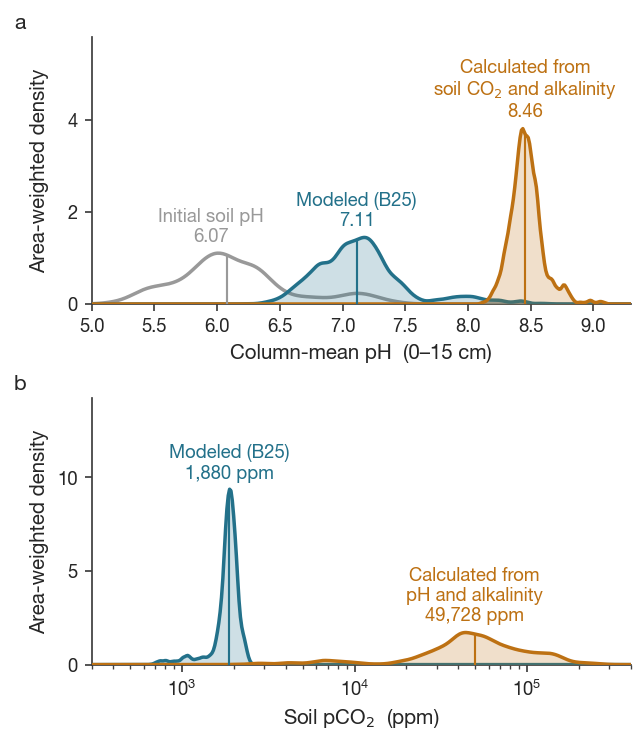

In [7]:
# Calculated curves close the carbonate system on a closed background (see experiments.closed_background):
#   alk_tot    = Alk_C(pH_ctrl, soil CO2) + rock-derived cation charge
#   pH_cb      = pH that carries alk_tot at B25's soil CO2         (no calcite step)
#   co2_req_cb = soil CO2 that carries alk_tot at B25's pH
# The same panels with B25's alkalinity as given are drawn in the last cell, for the supplement.
co2, wco2 = flat("soil_co2",   positive=True)
req, wreq = flat("co2_req_cb", positive=True)
ph0, w0   = flat("pH_diag")
ph1, w1   = flat("pH_cb")

# pH0 is a 7-layer CLM profile; mod5.m:157-166 interpolates it onto the 0-15 cm column.
CLM_DEPTHS = np.array([0, 5, 15, 30, 60, 100, 200]) / 100.
ZCOL = np.arange(0, .15 + 1e-9, .005) if DEPTH == "column" else np.array([.15])
phi = np.array([np.interp(ZCOL, CLM_DEPTHS, r).mean() for r in pt.pH0.values])
wi  = pt.area_ha.values

m_co2, m_req = wq(co2, wco2, .5), wq(req, wreq, .5)
mi, m0, m1   = wq(phi, wi, .5), wq(ph0, w0, .5), wq(ph1, w1, .5)
gt = lambda x, w, c=7.5: w[x > c].sum() / w.sum()   # area-weighted
x_, w_ = flat("co2_req_cb")
print(f"(closed background: {w_[x_ <= 0].sum() / w_.sum():.2%} of point-year area needs soil pCO2 <= 0 "
      f"and is left off panel b)")
print(f"soil pCO2 medians   modeled {m_co2:,.0f}   calculated {m_req:,.0f} ppm")
print(f"pH medians          initial {mi:.2f}   modeled {m0:.2f}   calculated {m1:.2f}")
for c in (7.5, 8.0):
    print(f"pH > {c}            initial {gt(phi, wi, c):.1%}   modeled {gt(ph0, w0, c):.1%}   "
          f"calculated {gt(ph1, w1, c):.1%}")


def inner(ax, x, w, m, color, label, log=True, dx=0, ls="-"):
    """Median as a solid line inside the distribution, `label` above the local peak."""
    t = np.log10 if log else (lambda v: v)
    k = gaussian_kde(t(x), weights=w)
    ax.vlines(m, 0, k(t(m))[0], color=color, lw=1.1, ls=ls, zorder=6)
    top = k(np.linspace(t(m) - .3, t(m) + .3, 61)).max()
    ax.annotate(label, xy=(m, top), xytext=(dx, 4), textcoords="offset points",
                color=color, ha="center", va="bottom", linespacing=1.15, zorder=7)

def ph_co2_fig(ph1, w1, req, wreq, stem=None, calc_label=True,
               ph_lim=(5.0, 9.3), co2_lim=(3e2, 4e5)):
    """The two-panel figure. `ph1` and `req` are the calculated pH and soil pCO2 (orange);
    the initial and modeled curves are the same in every version. Saved to panels/ when `stem`
    is given; `calc_label=False` leaves the orange curves unlabelled for the caller to place.
    `ph_lim` and `co2_lim` set each panel's x-range, which is also the range the densities are
    evaluated over (curves are cut at the edges, not extrapolated past them)."""
    m_req, m1 = wq(req, wreq, .5), wq(ph1, w1, .5)
    fig, (b, a) = plt.subplots(2, 1, figsize=(W["col15"], 5.2), layout="constrained")

    LO, HI = co2_lim
    density(a, co2, wco2, C["e0"],  lo=LO, hi=HI)
    density(a, req, wreq, C["req"], lo=LO, hi=HI, z=5)
    a.set_xscale("log"); a.set_xlim(LO, HI)
    a.set_ylim(0, a.get_ylim()[1] * 1.45)
    inner(a, co2, wco2, m_co2, C["e0"],  f"Modeled (B25)\n{m_co2:,.0f} ppm")
    if calc_label:
        inner(a, req, wreq, m_req, C["req"], f"Calculated from\npH and alkalinity\n{m_req:,.0f} ppm")
    a.set_xlabel("Soil pCO$_2$  (ppm)")

    LO, HI = ph_lim
    density(b, phi, wi, C["ctrl"], lo=LO, hi=HI, log=False, fill=0, z=2)
    density(b, ph0, w0, C["e0"],   lo=LO, hi=HI, log=False)
    density(b, ph1, w1, C["req"],  lo=LO, hi=HI, log=False, z=5)
    b.set_xlim(LO, HI)
    b.set_ylim(0, b.get_ylim()[1] * 1.45)
    inner(b, phi, wi, mi, C["ctrl"], f"Initial soil pH\n{mi:.2f}", log=False, dx=-8)
    inner(b, ph0, w0, m0, C["e0"],   f"Modeled (B25)\n{m0:.2f}", log=False)
    if calc_label:
        inner(b, ph1, w1, m1, C["req"],  f"Calculated from\nsoil CO$_2$ and alkalinity\n{m1:.2f}", log=False)
    b.set_xlabel(PH_LABEL)

    for ax, L in zip((b, a), "ab"):
        ax.set_ylabel("Area-weighted density")
        ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(3))
        ax.annotate(L, xy=(0, 1), xycoords="axes fraction", xytext=(-40, 12),
                    textcoords="offset points", fontweight="bold", fontsize=11,
                    va="top", ha="left")
    fig.align_ylabels((b, a))
    if stem:
        save(fig, stem)
    return fig, (b, a)

fig, (b, a) = ph_co2_fig(ph1, w1, req, wreq, "ph-soil-co2_" + CASE + SFX,
                         ph_lim=(5.0, 9.3), co2_lim=(3e2, 4e5))


In [4]:
# ---

## Supplement: B25's alkalinity as given

Repeating the main text figure, but add distributions for the soil pCO2 and pH calculated using B25's full alkalinity budget (i.e., without closing the initial porewater, `_cb`). This pushes the pCO2 and pH up because the initial porewater alkalinity is elevated because it is calculated from the same empirical buffer curve used to capture CDR. 

                             closed (main)  as given (supp)
pH median                             8.46             8.92
pH > 7.5                            100.0%            99.9%
pH > 8.0                            100.0%            98.8%
soil pCO2 median (ppm)              49,728          160,499
  x modeled                           26.4             85.4


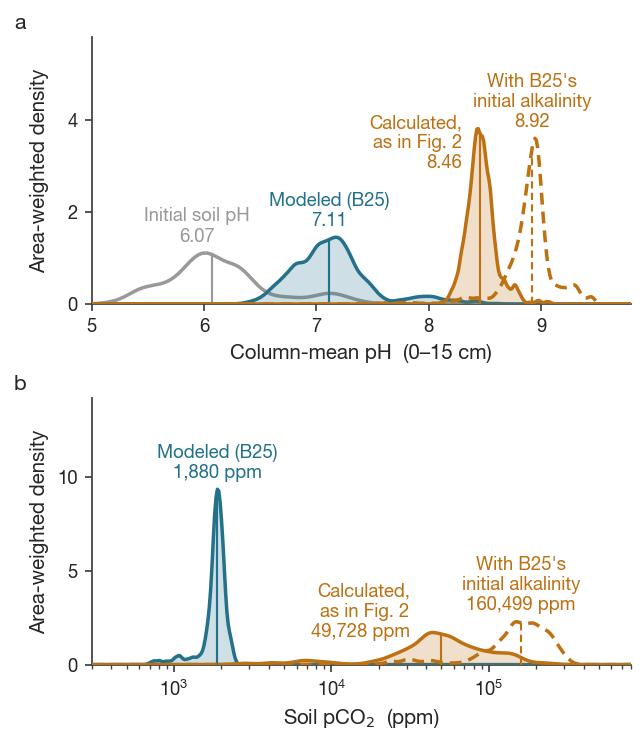

In [8]:
SUPP_PH = "pH_thermo"     # or "pH_e1": the earlier Fig 2a, with a thermodynamic calcite re-split
ph_t, w_t     = flat(SUPP_PH)
req_t, wreq_t = flat("co2_req", positive=True)

m_t, mr_t = wq(ph_t, w_t, .5), wq(req_t, wreq_t, .5)
print(f"{'':28s}{'closed (main)':>14s}{'as given (supp)':>17s}")
print(f"{'pH median':28s}{m1:>14.2f}{m_t:>17.2f}")
for c in (7.5, 8.0):
    print(f"{'pH > ' + str(c):28s}{gt(ph1, w1, c):>14.1%}{gt(ph_t, w_t, c):>17.1%}")
print(f"{'soil pCO2 median (ppm)':28s}{m_req:>14,.0f}{mr_t:>17,.0f}")
print(f"{'  x modeled':28s}{m_req / m_co2:>14.1f}{mr_t / m_co2:>17.1f}")

DASH = (0, (3.4, 2.0))

def side(ax, x, w, m, color, label, log=True, frac=.75, pad=5):
    """Median line as in `inner`, with `label` beside the curve's left flank at `frac` of its
    peak, so it clears the label stacked above the dashed curve."""
    t = np.log10 if log else (lambda v: v)
    k = gaussian_kde(t(x), weights=w)
    ax.vlines(m, 0, k(t(m))[0], color=color, lw=1.1, zorder=6)
    y = frac * k(np.linspace(t(m) - .3, t(m) + .3, 61)).max()
    g = np.linspace(t(m) - 1.5, t(m), 600)
    xl = g[np.argmax(k(g) >= y)]
    ax.annotate(label, xy=(10 ** xl if log else xl, y), xytext=(-pad, 0), textcoords="offset points",
                color=color, ha="right", va="bottom", linespacing=1.15, zorder=7)

def dashed(ax, x, w, log=True):
    """Unfilled dashed density over the current x-range; raises the y-limit if it peaks higher."""
    density(ax, x, w, C["req"], lo=ax.get_xlim()[0], hi=ax.get_xlim()[1], log=log,
            fill=0, ls=DASH, z=6)
    ax.set_ylim(0, max(ax.get_ylim()[1], 1.45 * ax.lines[-1].get_ydata().max()))

fig, (b, a) = ph_co2_fig(ph1, w1, req, wreq, calc_label=False,
                         ph_lim=(5.0, 9.8), co2_lim=(3e2, 8e5))
dashed(b, ph_t, w_t, log=False)
dashed(a, req_t, wreq_t)
side(b, ph1, w1, m1, C["req"], f"Calculated,\nas in Fig. 2\n{m1:.2f}", log=False)
inner(b, ph_t, w_t, m_t, C["req"], f"With B25's\ninitial alkalinity\n{m_t:.2f}", log=False, ls=DASH)
side(a, req, wreq, m_req, C["req"], f"Calculated,\nas in Fig. 2\n{m_req:,.0f} ppm")
inner(a, req_t, wreq_t, mr_t, C["req"], f"With B25's\ninitial alkalinity\n{mr_t:,.0f} ppm", ls=DASH)
save(fig, f"supp_ph-soil-co2_total-alk_{CASE}{SFX}")


In [ ]:
# ---